In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [4]:
df = pd.read_csv("Salary Data.csv")

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())
print(df.isnull().sum())

   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0
Dataset shape: (30, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes
None
YearsExperience    0
Salary             0
dtype: int64


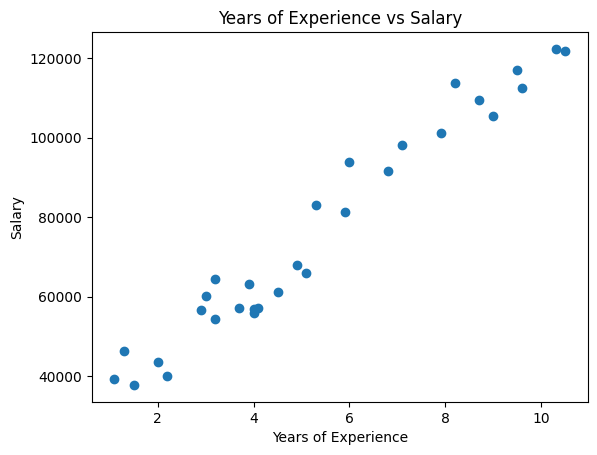

In [5]:
plt.scatter(df["YearsExperience"], df["Salary"])

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Years of Experience vs Salary")
plt.show()

In [6]:
X = df[["YearsExperience"]]
y = df["Salary"]

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features:
   YearsExperience
0              1.1
1              1.3
2              1.5
3              2.0
4              2.2

Target variable:
0    39343.0
1    46205.0
2    37731.0
3    43525.0
4    39891.0
Name: Salary, dtype: float64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 24
Testing samples: 6


In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [9]:
slope = model.coef_[0]
intercept = model.intercept_

print("Slope:", slope)
print("Intercept:", intercept)

print(f"Regression Equation: Salary = {intercept:.2f} + ({slope:.2f} * YearsExperience)")

Slope: 9423.815323030976
Intercept: 25321.583011776813
Regression Equation: Salary = 25321.58 + (9423.82 * YearsExperience)


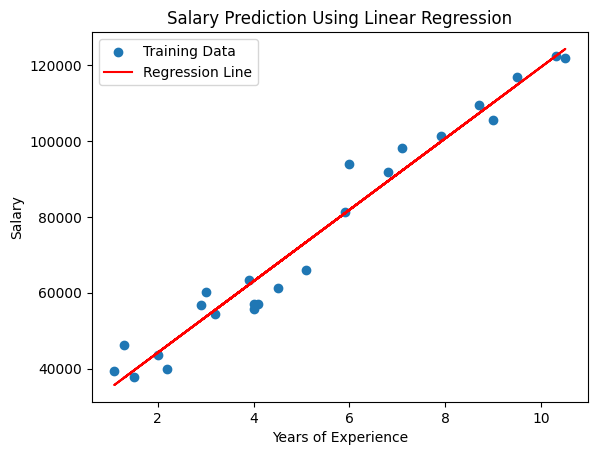

In [10]:
plt.scatter(X_train["YearsExperience"], y_train, label="Training Data")
plt.plot(
    X_train["YearsExperience"],
    model.predict(X_train),
    color="red",
    label="Regression Line"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary Prediction Using Linear Regression")
plt.legend()
plt.show()

In [11]:
experience = float(input("Enter years of experience: "))

predicted_salary = model.predict(
    pd.DataFrame({"YearsExperience": [experience]})
)

print(f"Predicted Salary: {predicted_salary[0]:.2f}")

Enter years of experience:  20


Predicted Salary: 213797.89


In [12]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("Model Evaluation")
print("-------------------------")
print("R2 Score:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

Model Evaluation
-------------------------
R2 Score: 0.9024461774180497
RMSE: 7059.04362190151
MAE: 6286.453830757749
